In [1]:
# =============================
# 1. Import libraries
# =============================
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# =============================
# 2. Load data
# =============================
file_path = "/mnt/f/Solar-Review-Ppaer/Monthwise-Data-Sheets/Data_clean/10-Minute-Average-Data/10-min-AVG-Data-miss.xlsx"
df = pd.read_excel(file_path)
df = df[['DateTime', 'Power_MW']]
df['Power_MW'] = df['Power_MW'].fillna(0)
df['DateTime'] = pd.to_datetime(df['DateTime'])
df.set_index('DateTime', inplace=True)

# =============================
# 3. Cyclic Features
# =============================
df['hour'] = df.index.hour
df['minute'] = df.index.minute
df['dayofweek'] = df.index.dayofweek
df['month'] = df.index.month

for col, max_val in zip(['hour','minute','dayofweek','month'], [23,59,6,12]):
    df[f'{col}_sin'] = np.sin(2*np.pi*df[col]/max_val)
    df[f'{col}_cos'] = np.cos(2*np.pi*df[col]/max_val)

# =============================
# 4. Decomposition Features
# =============================
# Additive
decomp_add = seasonal_decompose(df['Power_MW'], model='additive', period=144)
df['trend_add'] = decomp_add.trend
df['seasonal_add'] = decomp_add.seasonal
df['resid_add'] = decomp_add.resid

# Multiplicative
decomp_mul = seasonal_decompose(df['Power_MW'] + 1e-3, model='multiplicative', period=144)
df['trend_mul'] = decomp_mul.trend
df['seasonal_mul'] = decomp_mul.seasonal
df['resid_mul'] = decomp_mul.resid

# Fill NaNs
df = df.fillna(method='bfill').fillna(method='ffill')

# =============================
# 5. Scaling features
# =============================
feature_cols = [c for c in df.columns if c != 'Power_MW']
scaler = StandardScaler()
df[feature_cols] = scaler.fit_transform(df[feature_cols])

X = df[feature_cols].values
y = df['Power_MW'].values

# =============================
# 6. Random Forest Prediction
# =============================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
rf = RandomForestRegressor(n_estimators=1000, random_state=1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# =============================
# 7. Residuals & Derivative
# =============================
residuals = y_test - y_pred_rf
residuals_deriv = np.diff(residuals, prepend=residuals[0])  # same length

# Scale both residuals and derivative
resid_scaler = MinMaxScaler(feature_range=(-1,1))
deriv_scaler = MinMaxScaler(feature_range=(-1,1))

residuals_scaled = resid_scaler.fit_transform(residuals.reshape(-1,1))
residuals_deriv_scaled = deriv_scaler.fit_transform(residuals_deriv.reshape(-1,1))

# Combine both as LSTM input (2 features)
lstm_input = np.hstack((residuals_scaled, residuals_deriv_scaled))

# =============================
# 8. Prepare sequences for LSTM
# =============================
def create_sequences_multi(data, seq_length):
    X_seq, y_seq = [], []
    for i in range(len(data)-seq_length):
        X_seq.append(data[i:i+seq_length])
        y_seq.append(data[i+seq_length, 0])  # predict residual
    return np.array(X_seq), np.array(y_seq)

seq_length = 72  # 12 hours of 10-min data
X_seq, y_seq = create_sequences_multi(lstm_input, seq_length)

# Train/test split
split = int(len(X_seq)*0.8)
X_train_lstm, X_test_lstm = X_seq[:split], X_seq[split:]
y_train_lstm, y_test_lstm = y_seq[:split], y_seq[split:]

2025-09-27 08:11:37.655997: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-09-27 08:11:37.705275: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-09-27 08:11:38.972210: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

# =============================
# Define the BiLSTM model
# =============================
model = Sequential()

# First BiLSTM layer
model.add(Bidirectional(LSTM(32, activation='tanh', return_sequences=True), 
                        input_shape=(seq_length, 2)))
model.add(Dropout(0.3))

# Second BiLSTM layer
model.add(Bidirectional(LSTM(16, activation='tanh')))
model.add(Dropout(0.3))

# Output layer
model.add(Dense(1))

# Compile model
model.compile(optimizer='adam', loss='mse')

# =============================
# Early stopping callback
# =============================
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

# =============================
# Fit model with early stopping
# =============================
history = model.fit(
    X_train_lstm, 
    y_train_lstm, 
    epochs=200, 
    batch_size=64, 
    validation_split=0.1, 
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/89


/home/binayakcool009/miniconda3/envs/rapids_env/lib/python3.9/site-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0291 - val_loss: 0.0016
Epoch 2/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0027 - val_loss: 0.0014
Epoch 3/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0022 - val_loss: 0.0020
Epoch 4/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0021 - val_loss: 0.0021
Epoch 5/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0019 - val_loss: 0.0010
Epoch 6/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0011 - val_loss: 0.0013
Epoch 7/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0010 - val_loss: 8.6562e-04
Epoch 8/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 8.0737e-04 - val_loss: 0.0010
Epoch 9/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 6.3422e-04 - val_loss: 8.3763e-04
Epoch 10/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 5.2829e-04 - val_loss: 8.1976e-04
Epoch 11/89
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 4.6639e-04 - val_loss: 7.6320e-04
Epoch 12/89
145/145 

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# =============================
# 1. Hybrid Prediction
# =============================
# Predict residuals and inverse transform
y_pred_resid_scaled = model.predict(X_test_lstm).flatten()
y_pred_resid = resid_scaler.inverse_transform(y_pred_resid_scaled.reshape(-1,1)).flatten()

# Trim RF predictions to match residual length
y_pred_rf_trim = y_pred_rf[-len(y_pred_resid):]

# Final hybrid prediction in actual scale
y_final = y_pred_rf_trim + y_pred_resid
y_actual = y_test[-len(y_pred_resid):]

# =============================
# 2. Helper Functions
# =============================
def mase(y_true, y_pred):
    """
    Mean Absolute Scaled Error (MASE)
    """
    n = len(y_true)
    d = np.abs(np.diff(y_true)).mean()  # Naïve forecast error
    errors = np.abs(y_true - y_pred)
    return errors.mean() / d

def get_bootstrap_errors(y_true, y_pred, metric_func, n_boot=1000):
    """
    Bootstrap mean and standard deviation of error metrics
    """
    metrics = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = np.random.randint(0, n, n)
        metrics.append(metric_func(y_true[idx], y_pred[idx]))
    return np.mean(metrics), np.std(metrics)

# =============================
# 3. Metrics in Actual Scale (Bootstrap)
# =============================
# MAE
mae, mae_sd = get_bootstrap_errors(y_actual, y_final, mean_absolute_error)

# RMSE
rmse_func = lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred))
rmse, rmse_sd = get_bootstrap_errors(y_actual, y_final, rmse_func)

# R² (no SD, deterministic)
r2 = r2_score(y_actual, y_final)

# MASE
mase_val, mase_sd = get_bootstrap_errors(y_actual, y_final, mase)

# =============================
# 4. Print Results
# =============================
print("\nHybrid Model Results (Actual Scale):")
print(f"RMSE = {rmse:.4f} ± {rmse_sd:.4f}")
print(f"MAE  = {mae:.4f} ± {mae_sd:.4f}")
print(f"R²   = {r2:.4f}")
print(f"MASE = {mase_val:.4f} ± {mase_sd:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

Hybrid Model Results (Actual Scale):
RMSE = 0.6368 ± 0.0568
MAE  = 0.1681 ± 0.0137
R²   = 0.9809
MASE = 0.0351 ± 0.0031


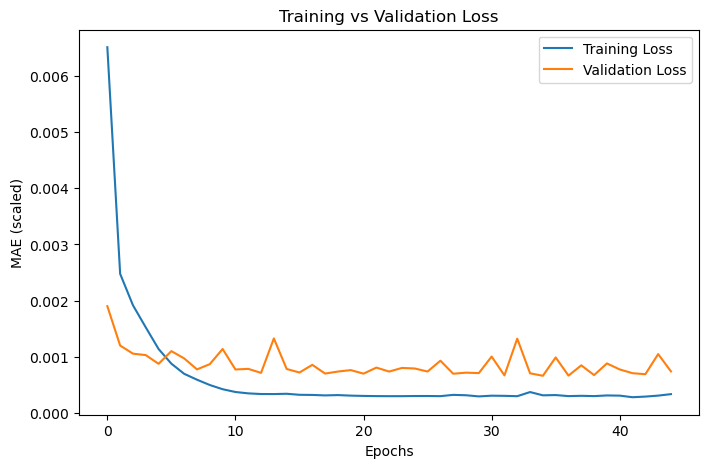

In [10]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("MAE (scaled)")
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =============================
# 1. Select a single day for plotting
# =============================
start_idx = 110                # start index of the day
end_idx = start_idx + 144 +144     # one day = 144 samples (10-min intervals)

y_test_day = y_actual[start_idx:end_idx]
y_pred_day = y_final[start_idx:end_idx]

# =============================
# 2. Confidence levels
# =============================
conf_levels = [0.95, 0.9, 0.8, 0.7, 0.6]

# =============================
# 3. Quantile-based intervals (tight, for metrics)
# =============================
intervals = {}
for cl in conf_levels:
    q = np.quantile(np.abs(y_test_day - y_pred_day), cl)
    L = y_pred_day - q
    U = y_pred_day + q
    intervals[cl] = (L, U)  # for metrics

# =============================
# 4. Widen intervals for visualization (optional)
# =============================
width_factor = 3.0
intervals_day = {}
for cl in conf_levels:
    L, U = intervals[cl]
    lower_wide = y_pred_day - (y_pred_day - L) * width_factor
    upper_wide = y_pred_day + (U - y_pred_day) * width_factor
    intervals_day[cl] = (lower_wide, upper_wide)  # only for plotting

# =============================
# 5. Metrics functions
# =============================
def picp(y_true, L, U):
    return np.mean((y_true >= L) & (y_true <= U))

def pinaw(L, U, R=None):
    R = R if R is not None else (np.max(y_test_day) - np.min(y_test_day))
    return np.mean(U - L) / R

def awd(y_true, L, U):
    awd_i = np.zeros_like(y_true)
    awd_i[y_true < L] = (L[y_true < L] - y_true[y_true < L]) / (U[y_true < L] - L[y_true < L])
    awd_i[y_true > U] = (y_true[y_true > U] - U[y_true > U]) / (U[y_true > U] - L[y_true > U])
    return np.mean(awd_i)


# =============================
# 7. Metrics table (tight intervals)
# =============================
results = []
for cl in conf_levels:
    L, U = intervals[cl]  # use tight intervals for metrics
    picp_val = picp(y_test_day, L, U)
    pinaw_val = pinaw(L, U)
    awd_val = awd(y_test_day, L, U)
    ace_val = abs(picp_val - cl)  # only ACE is absolute
    results.append([f"{int(cl*100)}%", picp_val*100, pinaw_val, awd_val, ace_val*100])

df_results = pd.DataFrame(results, columns=["Interval", "PICP (%)", "PINAW", "AWD", "ACE (%)"])
print(df_results)


  Interval   PICP (%)     PINAW       AWD   ACE (%)
0      95%  94.791667  0.053021  0.013307  0.208333
1      90%  89.930556  0.031672  0.047523  0.069444
2      80%  79.861111  0.019036  0.123850  0.138889
3      70%  69.791667  0.012551  0.251627  0.208333
4      60%  60.069444  0.006845  0.604420  0.069444


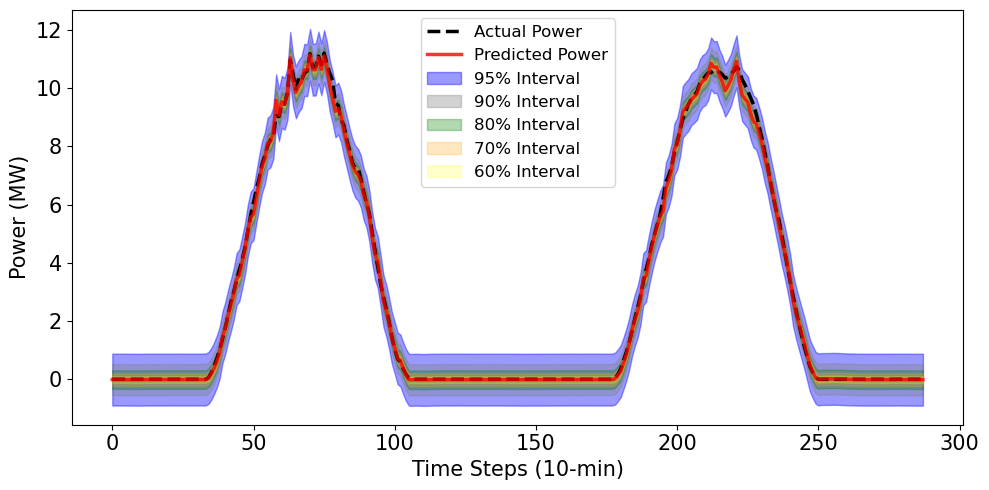

In [6]:
# =============================
# 6. Plotting
# =============================
fig, ax = plt.subplots(figsize=(10,5))

# Set axes background color to sky blue with alpha
#ax.set_facecolor((0.53, 0.81, 0.92, 0.3))  # RGB normalized + alpha

# Actual and predicted
ax.plot(y_test_day, label="Actual Power", color="black", linestyle='--', linewidth=2.5)
ax.plot(y_pred_day, label="Predicted Power", color="red", linewidth=2.5, alpha=0.8)

# Colors and alpha for CI fan
colors = {0.95: "blue", 0.9: "gray", 0.8: "green", 0.7: "orange", 0.6: "yellow"}
alphas = {0.95: 0.4, 0.9: 0.35, 0.8: 0.3, 0.7: 0.25, 0.6: 0.2}

# Plot CI bands from widest to narrowest
for cl in sorted(conf_levels, reverse=True):
    L, U = intervals_day[cl]
    ax.fill_between(range(len(y_test_day)), L, U, color=colors[cl], alpha=alphas[cl],
                    label=f"{int(cl*100)}% Interval")

ax.set_xlabel("Time Steps (10-min)", fontsize=15)
ax.set_ylabel("Power (MW)", fontsize=15)
ax.tick_params(axis='both', labelsize=15)
ax.legend(fontsize=12)
plt.tight_layout()
#plt.savefig("/mnt/f/Solar-Review-Ppaer/Result/power_prediction.png", dpi=300, bbox_inches='tight')  

plt.show()
